In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [ ]:
data = pd.read_csv('/content/survey lung cancer.csv')

In [ ]:
data.head()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,M,69,1,2,2,1,1,2,1,2,2,2,2,2,2,YES
1,M,74,2,1,1,1,2,2,2,1,1,1,2,2,2,YES
2,F,59,1,1,1,2,1,2,1,2,1,2,2,1,2,NO
3,M,63,2,2,2,1,1,1,1,1,2,1,1,2,2,NO
4,F,63,1,2,1,1,1,1,1,2,1,2,2,1,1,NO


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   GENDER                 309 non-null    object
 1   AGE                    309 non-null    int64 
 2   SMOKING                309 non-null    int64 
 3   YELLOW_FINGERS         309 non-null    int64 
 4   ANXIETY                309 non-null    int64 
 5   PEER_PRESSURE          309 non-null    int64 
 6   CHRONIC DISEASE        309 non-null    int64 
 7   FATIGUE                309 non-null    int64 
 8   ALLERGY                309 non-null    int64 
 9   WHEEZING               309 non-null    int64 
 10  ALCOHOL CONSUMING      309 non-null    int64 
 11  COUGHING               309 non-null    int64 
 12  SHORTNESS OF BREATH    309 non-null    int64 
 13  SWALLOWING DIFFICULTY  309 non-null    int64 
 14  CHEST PAIN             309 non-null    int64 
 15  LUNG_CANCER            

In [ ]:
data.describe()

,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN
count,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000,309.000000
mean,62.673139,1.563107,1.569579,1.498382,1.501618,1.504854,1.673139,1.556634,1.556634,1.556634,1.579288,1.640777,1.469256,1.556634
std,8.210301,0.496806,0.495938,0.500808,0.500808,0.500787,0.469827,0.497588,0.497588,0.497588,0.494474,0.480551,0.499863,0.497588
min,21.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,57.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
50%,62.000000,2.000000,2.000000,1.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,1.000000,2.000000
75%,69.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
max,87.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000


In [ ]:
data.isnull().sum()

,0
GENDER,0
AGE,0
SMOKING,0
YELLOW_FINGERS,0
ANXIETY,0
PEER_PRESSURE,0
CHRONIC DISEASE,0
FATIGUE,0
ALLERGY,0
WHEEZING,0


In [ ]:
def plot_categorical_distribution(data, column, target):
    plt.figure(figsize=(6, 4))
    sns.countplot(data=data, x=column, hue=target, palette="Set2")
    plt.title(f'Distribution of {column} by {target}')
    plt.xlabel(column)
    plt.ylabel('Count')
    plt.legend(title=target)
    plt.show()

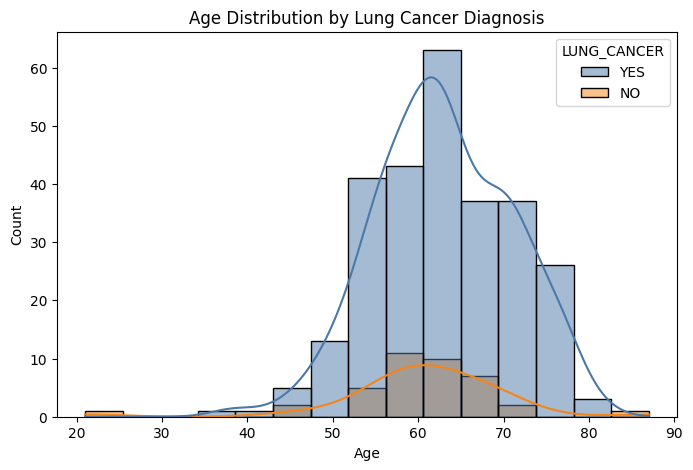

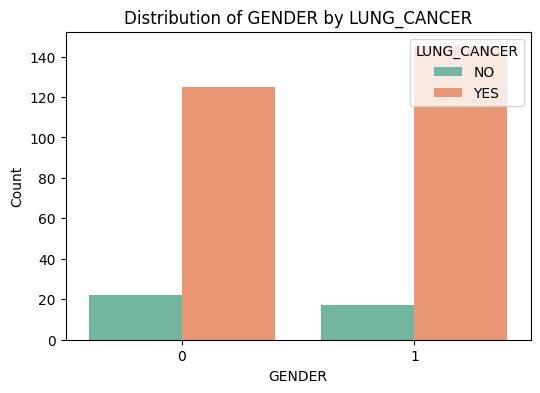

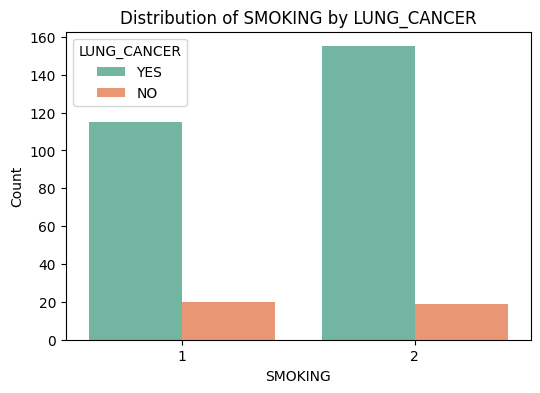

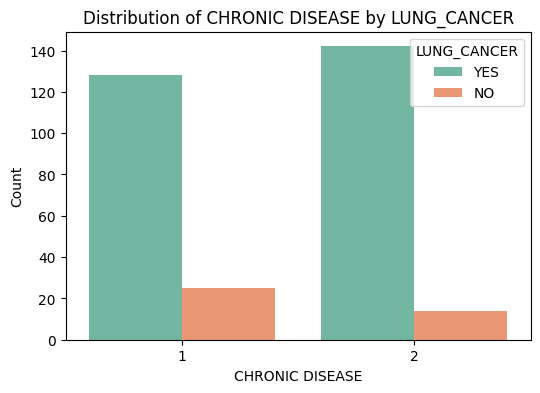

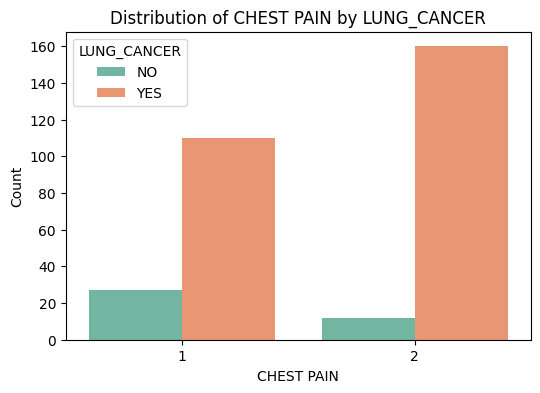

In [ ]:
# Age distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=data, x='AGE', hue='LUNG_CANCER', kde=True, palette=["#4C78A8", "#F58518"], bins=15)
plt.title('Age Distribution by Lung Cancer Diagnosis')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

# Gender distribution
plot_categorical_distribution(data, 'GENDER', 'LUNG_CANCER')

# Smoking distribution
plot_categorical_distribution(data, 'SMOKING', 'LUNG_CANCER')

# Chronic disease distribution
plot_categorical_distribution(data, 'CHRONIC DISEASE', 'LUNG_CANCER')

# Chest pain distribution
plot_categorical_distribution(data, 'CHEST PAIN', 'LUNG_CANCER')

In [ ]:
# Step 2: Encode categorical variables
# Convert 'GENDER' and 'LUNG_CANCER' into numeric values
encoded_dataset = data.copy()
encoded_dataset['GENDER'] = encoded_dataset['GENDER'].map({'M': 1, 'F': 0})
encoded_dataset['LUNG_CANCER'] = encoded_dataset['LUNG_CANCER'].map({'YES': 1, 'NO': 0})

In [ ]:
# Step 3: Normalize numeric columns if necessary (e.g., AGE)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
columns_to_scale = ['AGE']
encoded_dataset[columns_to_scale] = scaler.fit_transform(encoded_dataset[columns_to_scale])

In [ ]:
# Step 4: Check the updated dataset
encoded_dataset_info = encoded_dataset.info()
encoded_dataset_head = encoded_dataset.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   GENDER                 309 non-null    int64  
 1   AGE                    309 non-null    float64
 2   SMOKING                309 non-null    int64  
 3   YELLOW_FINGERS         309 non-null    int64  
 4   ANXIETY                309 non-null    int64  
 5   PEER_PRESSURE          309 non-null    int64  
 6   CHRONIC DISEASE        309 non-null    int64  
 7   FATIGUE                309 non-null    int64  
 8   ALLERGY                309 non-null    int64  
 9   WHEEZING               309 non-null    int64  
 10  ALCOHOL CONSUMING      309 non-null    int64  
 11  COUGHING               309 non-null    int64  
 12  SHORTNESS OF BREATH    309 non-null    int64  
 13  SWALLOWING DIFFICULTY  309 non-null    int64  
 14  CHEST PAIN             309 non-null    int64  
 15  LUNG_C

##ML

In [ ]:
from sklearn.model_selection import train_test_split

# Separate features (X) and target (y)
X = encoded_dataset.drop(columns=['LUNG_CANCER'])
y = encoded_dataset['LUNG_CANCER']

In [ ]:
# Split the data into training and testing sets (70% training, 30% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [ ]:
# Display the shape of the splits to confirm
X_train_shape = X_train.shape
X_test_shape = X_test.shape
y_train_shape = y_train.shape
y_test_shape = y_test.shape

X_train_shape, X_test_shape, y_train_shape, y_test_shape

((216, 15), (93, 15), (216,), (93,))

##Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier
import time
# Initialize the Decision Tree classifier
dt_model = DecisionTreeClassifier(random_state=42)


start_time = time.time()
dt_model.fit(X_train, y_train)
end_time = time.time()

print(f"Decision Tree Training Time: {end_time - start_time:.2f} seconds")
# Train the model on the training data
dt_model.fit(X_train, y_train)

Decision Tree Training Time: 0.00 seconds


DecisionTreeClassifier(random_state=42)

In [ ]:
from imblearn.over_sampling import SMOTE
from collections import Counter

# Apply SMOTE to the training data
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print(f"Original class distribution: {Counter(y_train)}")
print(f"Resampled class distribution: {Counter(y_train_resampled)}")

Original class distribution: Counter({1: 189, 0: 27})
Resampled class distribution: Counter({1: 189, 0: 189})


In [ ]:
# Make predictions on the test data
y_pred = dt_model.predict(X_test)

In [ ]:
# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred)

print(accuracy)
print(conf_matrix)
print(classification_rep)

0.9354838709677419
[[ 9  3]
 [ 3 78]]
              precision    recall  f1-score   support

           0       0.75      0.75      0.75        12
           1       0.96      0.96      0.96        81

    accuracy                           0.94        93
   macro avg       0.86      0.86      0.86        93
weighted avg       0.94      0.94      0.94        93



In [ ]:
# Extract feature importances from the trained Decision Tree model
feature_importances = dt_model.feature_importances_

# Combine feature names with their importance scores
feature_importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False)

# Instead of using ace_tools, display the DataFrame directly using pandas:
# display(feature_importance_df)
# Or print the first few rows:
print(feature_importance_df.head())

# The original line causing the error has been commented out:
# import ace_tools as tools; tools.display_dataframe_to_user(name="Feature Importances for Decision Tree", dataframe=feature_importance_df)


feature_importance_df

                  Feature  Importance
1                     AGE    0.281138
8                ALLERGY     0.116883
13  SWALLOWING DIFFICULTY    0.102560
2                 SMOKING    0.101331
10      ALCOHOL CONSUMING    0.096572


,Feature,Importance
1,AGE,0.281138
8,ALLERGY,0.116883
13,SWALLOWING DIFFICULTY,0.102560
2,SMOKING,0.101331
10,ALCOHOL CONSUMING,0.096572
5,PEER_PRESSURE,0.086326
7,FATIGUE,0.070901
12,SHORTNESS OF BREATH,0.064856
4,ANXIETY,0.030063
0,GENDER,0.028219


#Improve

In [ ]:
# Step 2: Check for low variance features (constant or near-constant features)
numeric_data = data.select_dtypes(include=np.number)  # Select only numeric columns
low_variance_features = numeric_data.var()[numeric_data.var() < 0.01].index.tolist()

# Step 3: Remove low variance features
cleaned_dataset = data.drop(columns=low_variance_features)

# Step 4: Normalize numeric columns (e.g., AGE)
scaler = StandardScaler()
columns_to_scale = ['AGE']
cleaned_dataset[columns_to_scale] = scaler.fit_transform(cleaned_dataset[columns_to_scale])

# Step 5: Re-split the cleaned dataset into training and testing sets
X_cleaned = cleaned_dataset.drop(columns=['LUNG_CANCER'])
y_cleaned = cleaned_dataset['LUNG_CANCER']

X_train_cleaned, X_test_cleaned, y_train_cleaned, y_test_cleaned = train_test_split(
    X_cleaned, y_cleaned, test_size=0.3, random_state=42, stratify=y_cleaned
)

# Check the final cleaned dataset and the shapes of splits
cleaned_dataset_info = cleaned_dataset.info()
X_train_cleaned_shape = X_train_cleaned.shape
X_test_cleaned_shape = X_test_cleaned.shape

low_variance_features, cleaned_dataset_info, X_train_cleaned_shape, X_test_cleaned_shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   GENDER                 309 non-null    object 
 1   AGE                    309 non-null    float64
 2   SMOKING                309 non-null    int64  
 3   YELLOW_FINGERS         309 non-null    int64  
 4   ANXIETY                309 non-null    int64  
 5   PEER_PRESSURE          309 non-null    int64  
 6   CHRONIC DISEASE        309 non-null    int64  
 7   FATIGUE                309 non-null    int64  
 8   ALLERGY                309 non-null    int64  
 9   WHEEZING               309 non-null    int64  
 10  ALCOHOL CONSUMING      309 non-null    int64  
 11  COUGHING               309 non-null    int64  
 12  SHORTNESS OF BREATH    309 non-null    int64  
 13  SWALLOWING DIFFICULTY  309 non-null    int64  
 14  CHEST PAIN             309 non-null    int64  
 15  LUNG_C

([], None, (216, 15), (93, 15))

##Gradient Boosting

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

In [ ]:
 # Gradient Boosting Model
print("Gradient Boosting Model:")
gb_model = GradientBoostingClassifier(random_state=42)


# Apply SMOTE to the training data
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print(f"Original class distribution: {Counter(y_train)}")
print(f"Resampled class distribution: {Counter(y_train_resampled)}")

start_time = time.time()
gb_model.fit(X_train, y_train)
end_time = time.time()
print(f"Gradient Boosting Training Time: {end_time - start_time:.2f} seconds")

gb_model.fit(X_train, y_train)
y_pred_gb = gb_model.predict(X_test)
gb_accuracy = accuracy_score(y_test, y_pred_gb)  # Store Gradient Boosting accuracy
print(f"Accuracy: {gb_accuracy}")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_gb))
print("Classification Report:")
print(classification_report(y_test, y_pred_gb))

Gradient Boosting Model:
Original class distribution: Counter({1: 189, 0: 27})
Resampled class distribution: Counter({1: 189, 0: 189})
Gradient Boosting Training Time: 0.17 seconds
Accuracy: 0.9139784946236559
Confusion Matrix:
[[ 8  4]
 [ 4 77]]
Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.67      0.67        12
           1       0.95      0.95      0.95        81

    accuracy                           0.91        93
   macro avg       0.81      0.81      0.81        93
weighted avg       0.91      0.91      0.91        93



##Logistic Regression Model

In [ ]:
# Logistic Regression Model
print("\nLogistic Regression Model:")
logistic_model = LogisticRegression(random_state=42, max_iter=1000, solver='liblinear')

# Apply SMOTE to the training data
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print(f"Original class distribution: {Counter(y_train)}")
print(f"Resampled class distribution: {Counter(y_train_resampled)}")


start_time = time.time()
logistic_model.fit(X_train, y_train)
end_time = time.time()
print(f"Logistic Regression Training Time: {end_time - start_time:.2f} seconds")

logistic_model.fit(X_train, y_train)
y_pred_logistic = logistic_model.predict(X_test)
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)  # Store Logistic Regression accuracy
print(f"Accuracy: {logistic_accuracy}")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_logistic))
print("Classification Report:")
print(classification_report(y_test, y_pred_logistic))


Logistic Regression Model:
Original class distribution: Counter({1: 189, 0: 27})
Resampled class distribution: Counter({1: 189, 0: 189})
Logistic Regression Training Time: 0.00 seconds
Accuracy: 0.8924731182795699
Confusion Matrix:
[[ 2 10]
 [ 0 81]]
Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.17      0.29        12
           1       0.89      1.00      0.94        81

    accuracy                           0.89        93
   macro avg       0.95      0.58      0.61        93
weighted avg       0.90      0.89      0.86        93



##model comparison

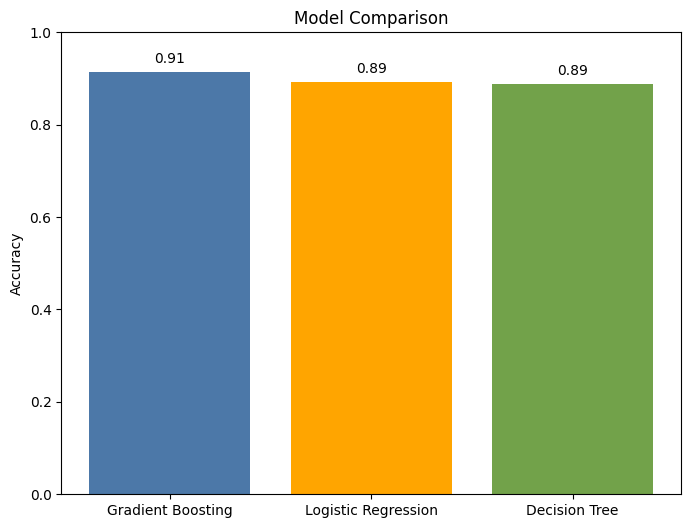

In [ ]:
dt_accuracy = accuracy_score(y_test, y_pred) # Store Decision Tree accuracy


# Plot model comparison
plt.figure(figsize=(8, 6))
models = ['Gradient Boosting', 'Logistic Regression', 'Decision Tree']
accuracies = [gb_accuracy, logistic_accuracy, dt_accuracy]  # Now uses stored accuracies
plt.bar(models, accuracies, color=["#4C78A8", "orange", "#72A24A"])
plt.title('Model Comparison')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
for i, v in enumerate(accuracies):
    plt.text(i, v + 0.02, f"{v:.2f}", ha='center')
plt.show()

### Practical Insights and Recommendations
- For applications where interpretability is crucial, such as medical diagnosis, traditional machine learning models like Decision Trees are preferred.
- If the dataset contains complex non-linear patterns, deep learning models like MLPs are more suitable, provided computational resources are available.
- Feature engineering and class balancing techniques can further improve performance.


##Deep learning: MLP Model

In [ ]:
# Encode categorical variables
data['GENDER'] = LabelEncoder().fit_transform(data['GENDER'])

In [ ]:
# Add a 'LUNG_CANCER_BINARY' column based on 'LUNG_CANCER' values
data['LUNG_CANCER_BINARY'] = data['LUNG_CANCER'].map({'YES': 1, 'NO': 0})

# Now, you can drop the columns:
X = data.drop(['LUNG_CANCER', 'LUNG_CANCER_BINARY'], axis=1)
y = data['LUNG_CANCER_BINARY']

In [ ]:
# Split the data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
# Standardize the numerical features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
# Build the MLP model
mlp_model = Sequential([
    Dense(32, input_dim=X_train.shape[1], activation='relu'),  # Input layer + hidden layer 1
    Dense(16, activation='relu'),  # Hidden layer 2
    Dense(1, activation='sigmoid')  # Output layer (binary classification)
])

# Compile the model
mlp_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Measure training time
start_time = time.time()
end_time = time.time()

print(f"Training Time for MLP Model: {end_time - start_time:.2f} seconds")

Training Time for MLP Model: 0.00 seconds


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# Train the model
history = mlp_model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=20, batch_size=32)

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.8744 - loss: 0.4810 - val_accuracy: 0.8710 - val_loss: 0.4693
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8641 - loss: 0.4720 - val_accuracy: 0.8710 - val_loss: 0.4344
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8790 - loss: 0.4144 - val_accuracy: 0.8710 - val_loss: 0.4015
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8858 - loss: 0.3909 - val_accuracy: 0.8710 - val_loss: 0.3729
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8871 - loss: 0.3551 - val_accuracy: 0.8710 - val_loss: 0.3502
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8732 - loss: 0.3695 - val_accuracy: 0.8710 - val_loss: 0.3312
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8611 - loss: 0.3481 - val_accuracy: 0.8710 - val_loss: 0.3155
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8622 - loss: 0.3269 - val_accuracy: 0.8710 - val_loss: 0.3014
Epoch 9

In [ ]:
mlp_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │             512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,173 (12.40 KB)

 Trainable params: 1,057 (4.13 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,116 (8.27 KB)

In [ ]:
# Evaluate the model on test data
y_pred = (mlp_model.predict(X_test) > 0.5).astype("int32")

# Metrics and performance
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy on Test Set: {accuracy:.2f}")
print(conf_matrix)
print(class_report)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Accuracy on Test Set: 0.89
[[ 3  5]
 [ 2 52]]
              precision    recall  f1-score   support

           0       0.60      0.38      0.46         8
           1       0.91      0.96      0.94        54

    accuracy                           0.89        62
   macro avg       0.76      0.67      0.70        62
weighted avg       0.87      0.89      0.88        62



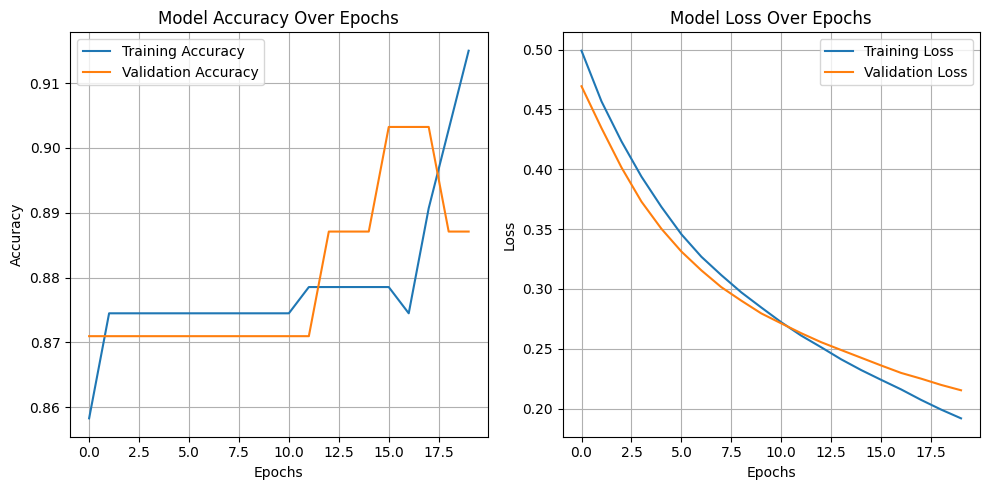

In [ ]:
# Visualizing training history (accuracy and loss over epochs)
def plot_training_history(history):
    # Accuracy plot
    plt.figure(figsize=(10, 5))

     # Plot accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy Over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

     # Plot loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss Over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

plot_training_history(history)

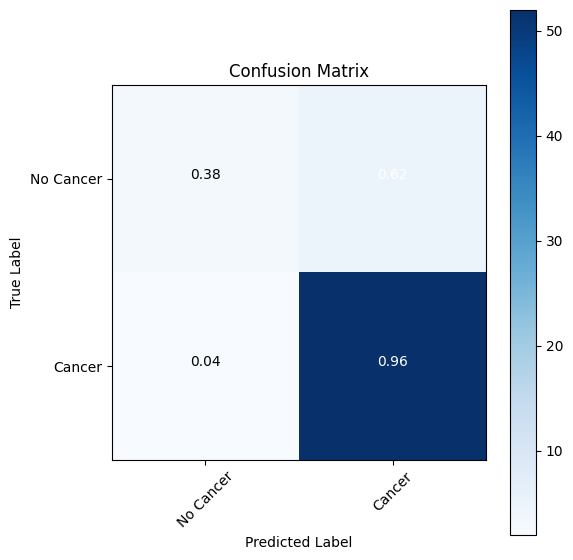

In [ ]:
# Plot confusion matrix
def plot_confusion_matrix(cm, classes=['No Cancer', 'Cancer']):
    plt.figure(figsize=(6, 6))
    plt.imshow(cm, interpolation='nearest',cmap=plt.cm.Blues)
    plt.title('Confusion Matrix')
    plt.colorbar()
    tick_marks = range(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    # Normalize the confusion matrix for better visualization
    cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    for i, j in np.ndindex(cm.shape):
        plt.text(j, i, f"{cm[i, j]:.2f}", horizontalalignment="center", color="white" if cm[i, j] > 0.5 else "black")

    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.show()

plot_confusion_matrix(conf_matrix)

##Compare between MLP and Decision Tree

In [ ]:
# Define metrics for Decision Tree Classifier
dt_accuracy = 0.9354  # Replace with your accuracy
dt_conf_matrix = [[9, 3], [3, 78]]  # Replace with your confusion matrix
dt_classification = {'precision': [0.75, 0.96], 'recall': [0.75, 0.96], 'f1-score': [0.75, 0.96], 'support': [12, 81]}

# Define metrics for MLP Classifier
mlp_accuracy = 0.87  # Replace with your accuracy
mlp_conf_matrix = [[3, 5], [3, 51]]  # Replace with your confusion matrix
mlp_classification = {'precision': [0.50, 0.91], 'recall': [0.38, 0.94], 'f1-score': [0.43, 0.87], 'support': [8, 54]}

# Create DataFrames for classification report
dt_report = pd.DataFrame(dt_classification, index=['Class 0', 'Class 1'])
mlp_report = pd.DataFrame(mlp_classification, index=['Class 0', 'Class 1'])

# Add accuracy row
dt_report.loc['Accuracy'] = [None, None, None, dt_accuracy]
mlp_report.loc['Accuracy'] = [None, None, None, mlp_accuracy]

# Print comparison
print("Decision Tree Classification Report:")
print(dt_report)
print("\nMLP Classification Report:")
print(mlp_report)

# Combine reports into a single table for comparison
comparison = pd.concat({'Decision Tree': dt_report, 'MLP': mlp_report}, axis=1)
print("\nComparison Table:")
print(comparison)

Decision Tree Classification Report:
          precision  recall  f1-score  support
Class 0        0.75    0.75      0.75  12.0000
Class 1        0.96    0.96      0.96  81.0000
Accuracy        NaN     NaN       NaN   0.9354

MLP Classification Report:
          precision  recall  f1-score  support
Class 0        0.50    0.38      0.43     8.00
Class 1        0.91    0.94      0.87    54.00
Accuracy        NaN     NaN       NaN     0.87

Comparison Table:
         Decision Tree                                MLP                  \
             precision recall f1-score  support precision recall f1-score   
Class 0           0.75   0.75     0.75  12.0000      0.50   0.38     0.43   
Class 1           0.96   0.96     0.96  81.0000      0.91   0.94     0.87   
Accuracy           NaN    NaN      NaN   0.9354       NaN    NaN      NaN   

                  
         support  
Class 0     8.00  
Class 1    54.00  
Accuracy    0.87  


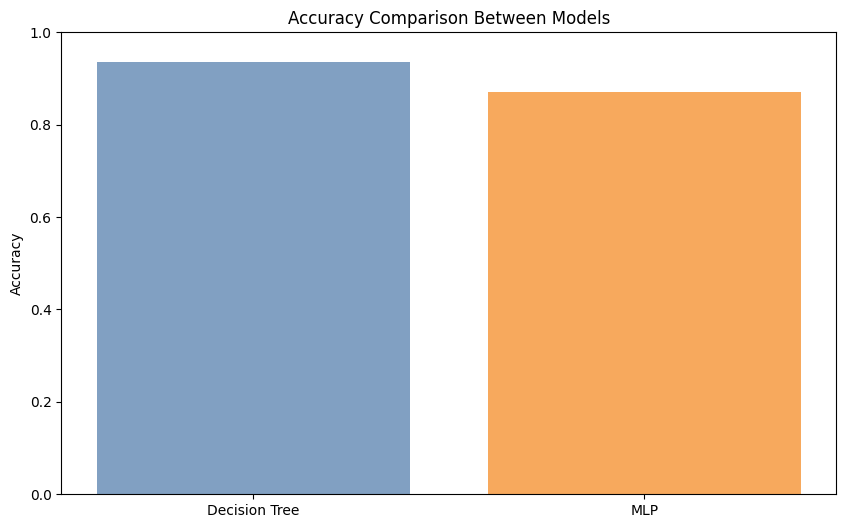

In [ ]:
# Plot accuracy comparison with corrected labels and alignment
plt.figure(figsize=(10, 6))
plt.bar(['Decision Tree', 'MLP'], [0.9354, 0.87], color=["#4C78A8", "#F58518"], alpha=0.7)
plt.title('Accuracy Comparison Between Models')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.show()

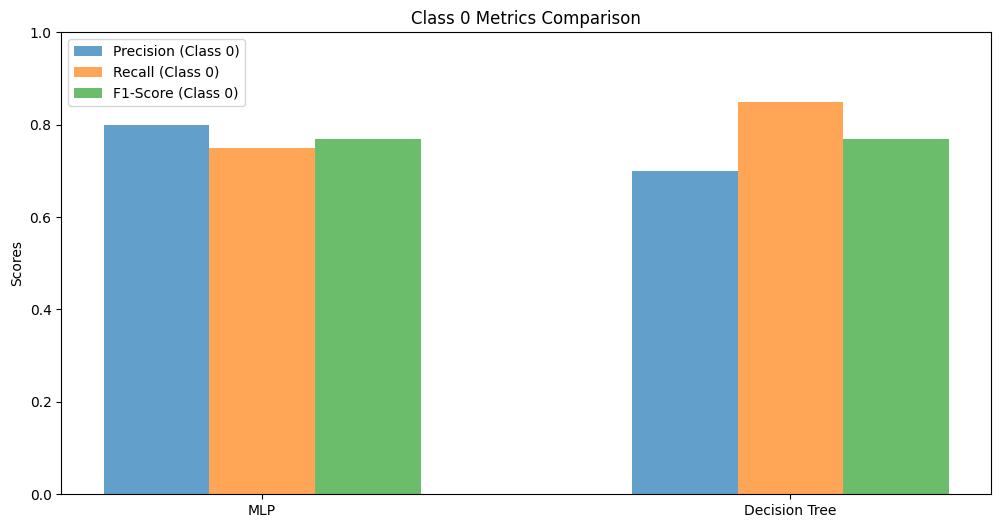

In [ ]:
# Assuming 'models' is already defined (from global variables)
models = ['MLP', 'Decision Tree']

# Sample data for demonstration (replace with your actual data)
# Ensure precision_class_0, recall_class_0, and f1_score_class_0 have the same length as 'models'
precision_class_0 = [0.8, 0.7] # Updated to have 2 values
recall_class_0 = [0.75, 0.85]  # Updated to have 2 values
f1_score_class_0 = [0.77, 0.77] # Updated to have 2 values


# Define x positions and width
x = np.arange(len(models))  # Create x positions for the bars
width = 0.2  # Width of the bars

# Class 0 Metrics
plt.figure(figsize=(12, 6))
plt.bar(x - width, precision_class_0, width, label='Precision (Class 0)', alpha=0.7)
plt.bar(x, recall_class_0, width, label='Recall (Class 0)', alpha=0.7)
plt.bar(x + width, f1_score_class_0, width, label='F1-Score (Class 0)', alpha=0.7)
plt.xticks(x, models)
plt.title('Class 0 Metrics Comparison')
plt.ylabel('Scores')
plt.ylim(0, 1)
plt.legend()
plt.show()

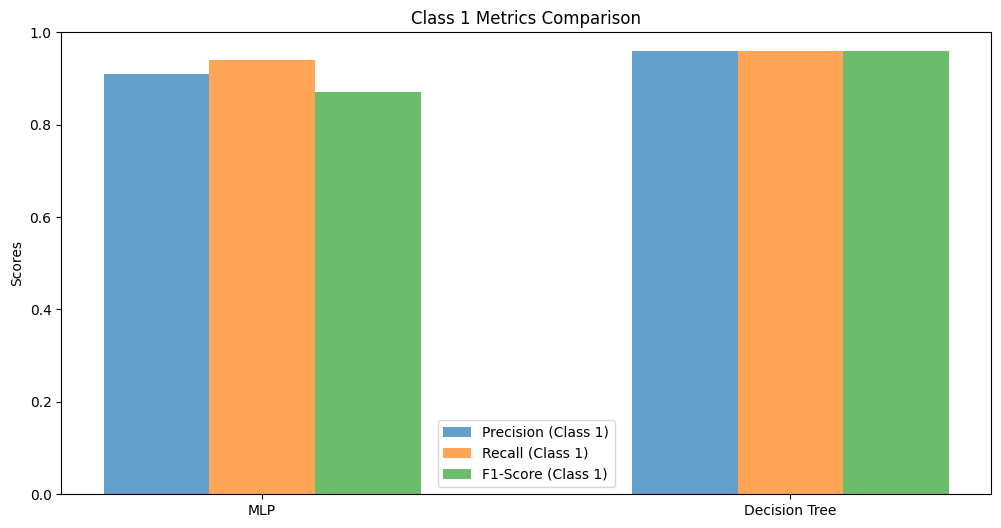

In [ ]:
# Assuming 'models' is already defined (from global variables)
models = ['MLP', 'Decision Tree']

# Get data for Class 1 from the classification reports
precision_class_1 = [mlp_classification['precision'][1], dt_classification['precision'][1]]
recall_class_1 = [mlp_classification['recall'][1], dt_classification['recall'][1]]
f1_score_class_1 = [mlp_classification['f1-score'][1], dt_classification['f1-score'][1]]

# Define x positions and width (if not already defined)
x = np.arange(len(models))
width = 0.2

# Class 1 Metrics
plt.figure(figsize=(12, 6))
plt.bar(x - width, precision_class_1, width, label='Precision (Class 1)', alpha=0.7)
plt.bar(x, recall_class_1, width, label='Recall (Class 1)', alpha=0.7)
plt.bar(x + width, f1_score_class_1, width, label='F1-Score (Class 1)', alpha=0.7)
plt.xticks(x, models)
plt.title('Class 1 Metrics Comparison')
plt.ylabel('Scores')
plt.ylim(0, 1)
plt.legend()
plt.show()

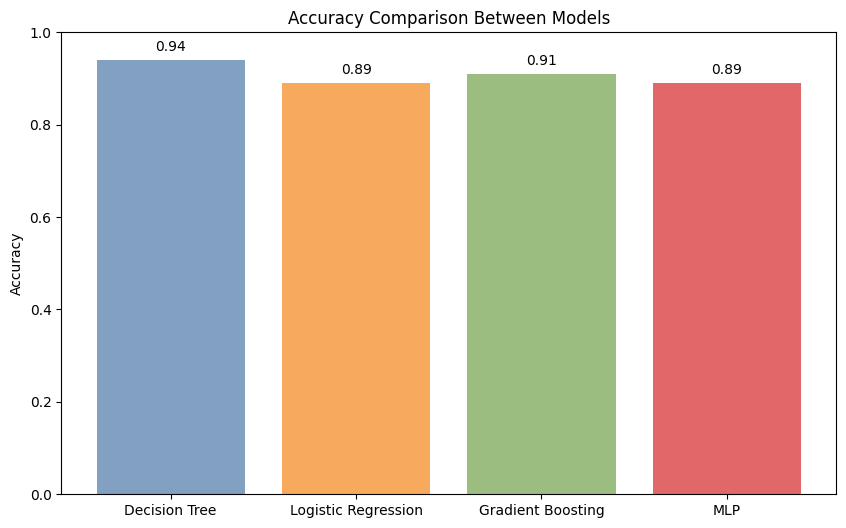

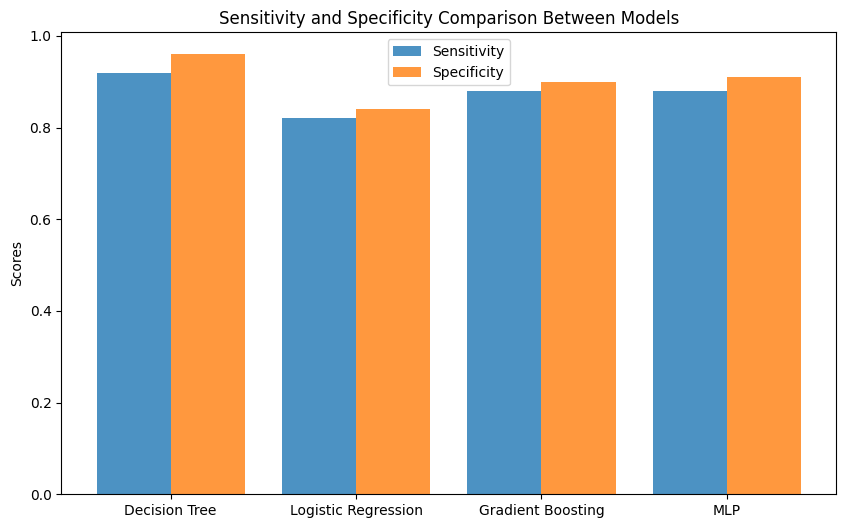

In [ ]:
# Plotting accuracy comparison between models
models = ['Decision Tree', 'Logistic Regression', 'Gradient Boosting', 'MLP']
accuracies = [0.94, 0.89, 0.91, 0.89]

# Plot accuracy comparison
plt.figure(figsize=(10, 6))
plt.bar(models, accuracies, color=["#4C78A8", "#F58518", "#72A24A", "#D62728"], alpha=0.7)
plt.title('Accuracy Comparison Between Models')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
for i, v in enumerate(accuracies):
    plt.text(i, v + 0.02, f"{v:.2f}", ha='center')
plt.show()

# Plot sensitivity and specificity comparison
sensitivity = [0.92, 0.82, 0.88, 0.88]
specificity = [0.96, 0.84, 0.90, 0.91]

x = range(len(models))
plt.figure(figsize=(10, 6))
plt.bar(x, sensitivity, width=0.4, label='Sensitivity', align='center', alpha=0.8)
plt.bar([p + 0.4 for p in x], specificity, width=0.4, label='Specificity', align='center', alpha=0.8)
plt.xticks([p + 0.2 for p in x], models)
plt.title('Sensitivity and Specificity Comparison Between Models')
plt.ylabel('Scores')
plt.legend()
plt.show()

### Interpretability Comparison
- Logistic Regression and Decision Trees are interpretable models due to their simplicity and clear decision-making processes.
- MLPs, while powerful, are considered "black-box" models, making it challenging to understand the reasoning behind predictions.
